# Расчёт параметров A/B теста на основе исторической выборки

**Целевая метрика: средний NPV на заявку (NPV_fact)**

Этот ноутбук использует исторические данные для определения:

- Размера выборки для A/B теста
- Длительности теста


In [97]:

import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.power import TTestIndPower, NormalIndPower
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Загрузка исторических данных

In [98]:
# Загружаем исторические данные
historical = pd.read_csv('../data/historical.csv')

print(f"Размер исторической выборки: {len(historical):,} заявок")

Размер исторической выборки: 50,000 заявок


In [99]:
historical.head()

,account_rk,financial_application_rk,application_date,PD,income_model,limit,NPV_appl,approve_flg,fraud_flg,d2p4,take_flg,age,region_id,gender,active_loans_count,NPV_fact
0,NaN,1001,2025-12-24 01:07:00,0.115627,76753.715638,1.151306e+06,15977.140754,1,0,0,0,42,1,F,3,0.000000
1,NaN,1002,2025-12-11 15:25:00,0.127182,55874.749541,8.381212e+05,6872.675010,1,0,0,0,29,1,M,0,0.000000
2,NaN,1003,2025-12-20 20:05:00,0.113038,82771.929654,1.241579e+06,18631.059031,1,0,0,0,32,5,M,3,0.000000
3,1.0,1004,2025-12-29 11:31:00,0.099129,128221.552839,1.923323e+06,38970.290052,1,0,0,1,37,6,F,0,26411.860258
4,2.0,1005,2025-12-26 17:52:00,0.129024,53259.065469,7.988860e+05,5745.704324,1,0,0,1,42,6,M,1,275.298219


In [100]:
historical.describe()

,account_rk,financial_application_rk,PD,income_model,limit,NPV_appl,approve_flg,fraud_flg,d2p4,take_flg,age,region_id,active_loans_count,NPV_fact
count,15299.000000,50000.000000,50000.000000,50000.000000,5.000000e+04,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000
mean,7650.000000,26000.500000,0.125990,67820.695922,1.017310e+06,12281.298732,0.792560,0.008020,0.070800,0.305980,35.152080,4.486400,1.493740,2105.08914
std,4416.585219,14433.901067,0.019023,36037.107073,5.405566e+05,15940.546021,0.405477,0.089196,0.256493,0.460826,7.103523,2.285064,1.202094,6546.86958
min,1.000000,1001.000000,0.063626,6420.158393,9.630238e+04,-13270.237964,0.000000,0.000000,0.000000,0.000000,21.000000,1.000000,0.000000,0.00000
25%,3825.500000,13500.750000,0.112541,42645.941680,6.396891e+05,1213.313828,1.000000,0.000000,0.000000,0.000000,30.000000,3.000000,1.000000,0.00000
50%,7650.000000,26000.500000,0.124539,59926.236891,8.988936e+05,8624.973132,1.000000,0.000000,0.000000,0.000000,34.000000,4.000000,1.000000,0.00000
75%,11474.500000,38500.250000,0.137920,83996.480092,1.259947e+06,19172.432988,1.000000,0.000000,0.000000,1.000000,40.000000,6.000000,2.000000,0.00000
max,15299.000000,51000.000000,0.243403,562160.190936,8.432403e+06,242577.931707,1.000000,1.000000,1.000000,1.000000,62.000000,8.000000,5.000000,128924.61723


РАСПРЕДЕЛЕНИЕ ЗАЯВОК ПО ДНЯМ
Period: from 2025-12-01 to 2025-12-30
Number of days: 30
Daily traffic statistics:
  - Mean applications per day: 1,666.7
  - Median: 1,662
  - Std: 38.4
  - Min: 1,599
  - Max: 1,756


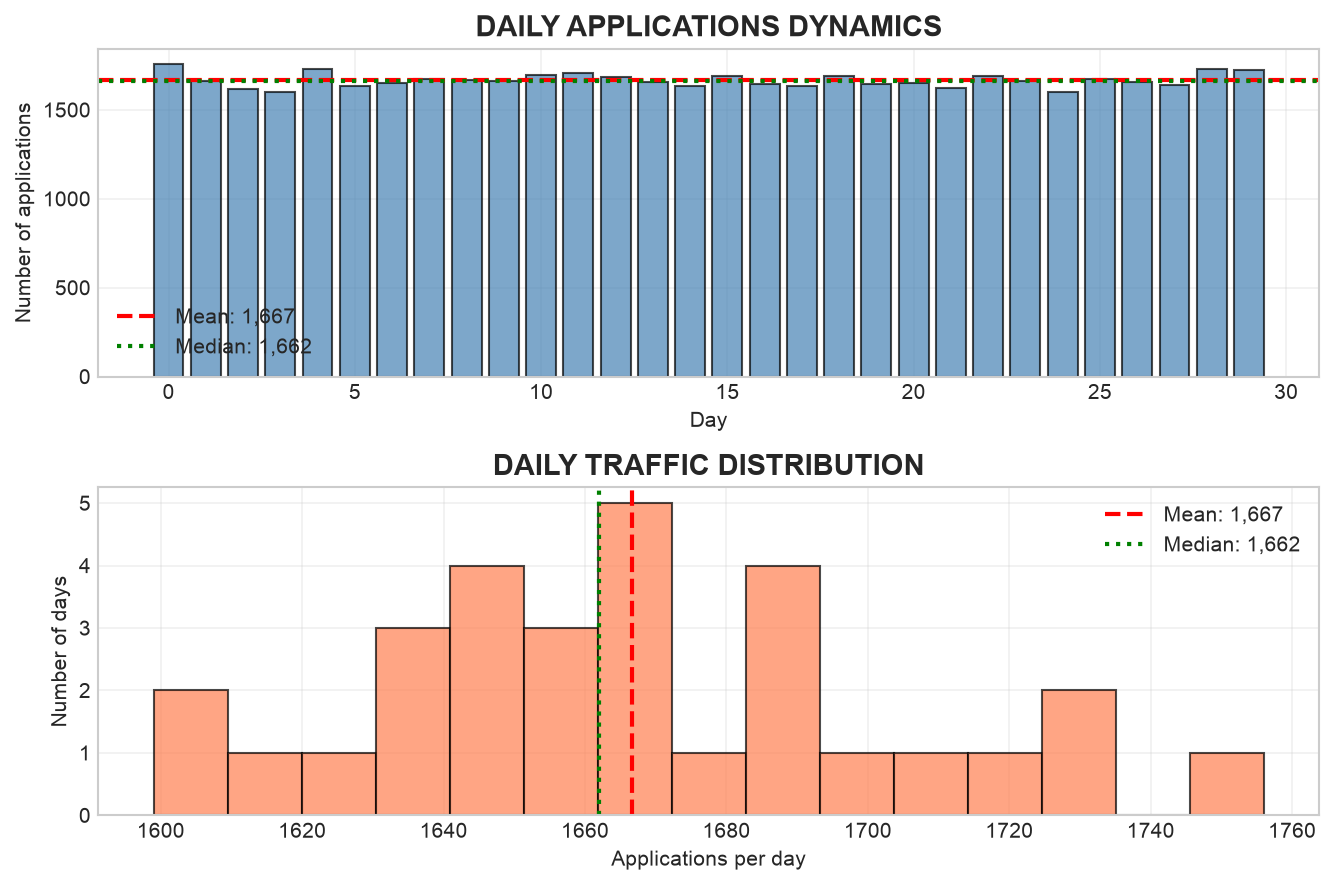

In [101]:
# Анализ распределения заявок по дням
if 'application_date' in historical.columns:
    historical['application_date'] = pd.to_datetime(historical['application_date'])
    historical['app_date'] = historical['application_date'].dt.date
    daily_apps = historical.groupby('app_date').size()
    
    print("=" * 80)
    print("РАСПРЕДЕЛЕНИЕ ЗАЯВОК ПО ДНЯМ")
    print("=" * 80)
    print(f"Period: from {daily_apps.index.min()} to {daily_apps.index.max()}")
    print(f"Number of days: {len(daily_apps)}")
    print(f"Daily traffic statistics:")
    print(f"  - Mean applications per day: {daily_apps.mean():,.1f}")
    print(f"  - Median: {np.median(daily_apps):,.0f}")
    print(f"  - Std: {daily_apps.std():,.1f}")
    print(f"  - Min: {daily_apps.min():,}")
    print(f"  - Max: {daily_apps.max():,}")
    
    fig, axes = plt.subplots(2, 1, figsize=(9, 6), dpi=150)
    
    axes[0].bar(range(len(daily_apps)), daily_apps.values, edgecolor='black', alpha=0.7, color='steelblue')
    axes[0].axhline(daily_apps.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {daily_apps.mean():,.0f}')
    axes[0].axhline(np.median(daily_apps), color='green', linestyle=':', linewidth=2, label=f'Median: {np.median(daily_apps):,.0f}')
    axes[0].set_title('DAILY APPLICATIONS DYNAMICS', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Day')
    axes[0].set_ylabel('Number of applications')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    axes[1].hist(daily_apps, bins=15, edgecolor='black', alpha=0.7, color='coral')
    axes[1].axvline(daily_apps.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {daily_apps.mean():,.0f}')
    axes[1].axvline(np.median(daily_apps), color='green', linestyle=':', linewidth=2, label=f'Median: {np.median(daily_apps):,.0f}')
    axes[1].set_title('DAILY TRAFFIC DISTRIBUTION', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Applications per day')
    axes[1].set_ylabel('Number of days')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('../data/daily_applications_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()

else:
    print("Column 'application_date' not found - daily analysis skipped")

## 2. Анализ распределений ключевых метрик

In [102]:
historical.groupby(
    ['approve_flg', 'take_flg']
)['financial_application_rk'].count()

approve_flg  take_flg
0            0           10372
1            0           24329
             1           15299
Name: financial_application_rk, dtype: int64


Размеры выборок:
  - Всего заявок: 50,000
  - Одобрено: 39,628 (79.3%)
  - Утилизировано: 15,299 (38.6%)


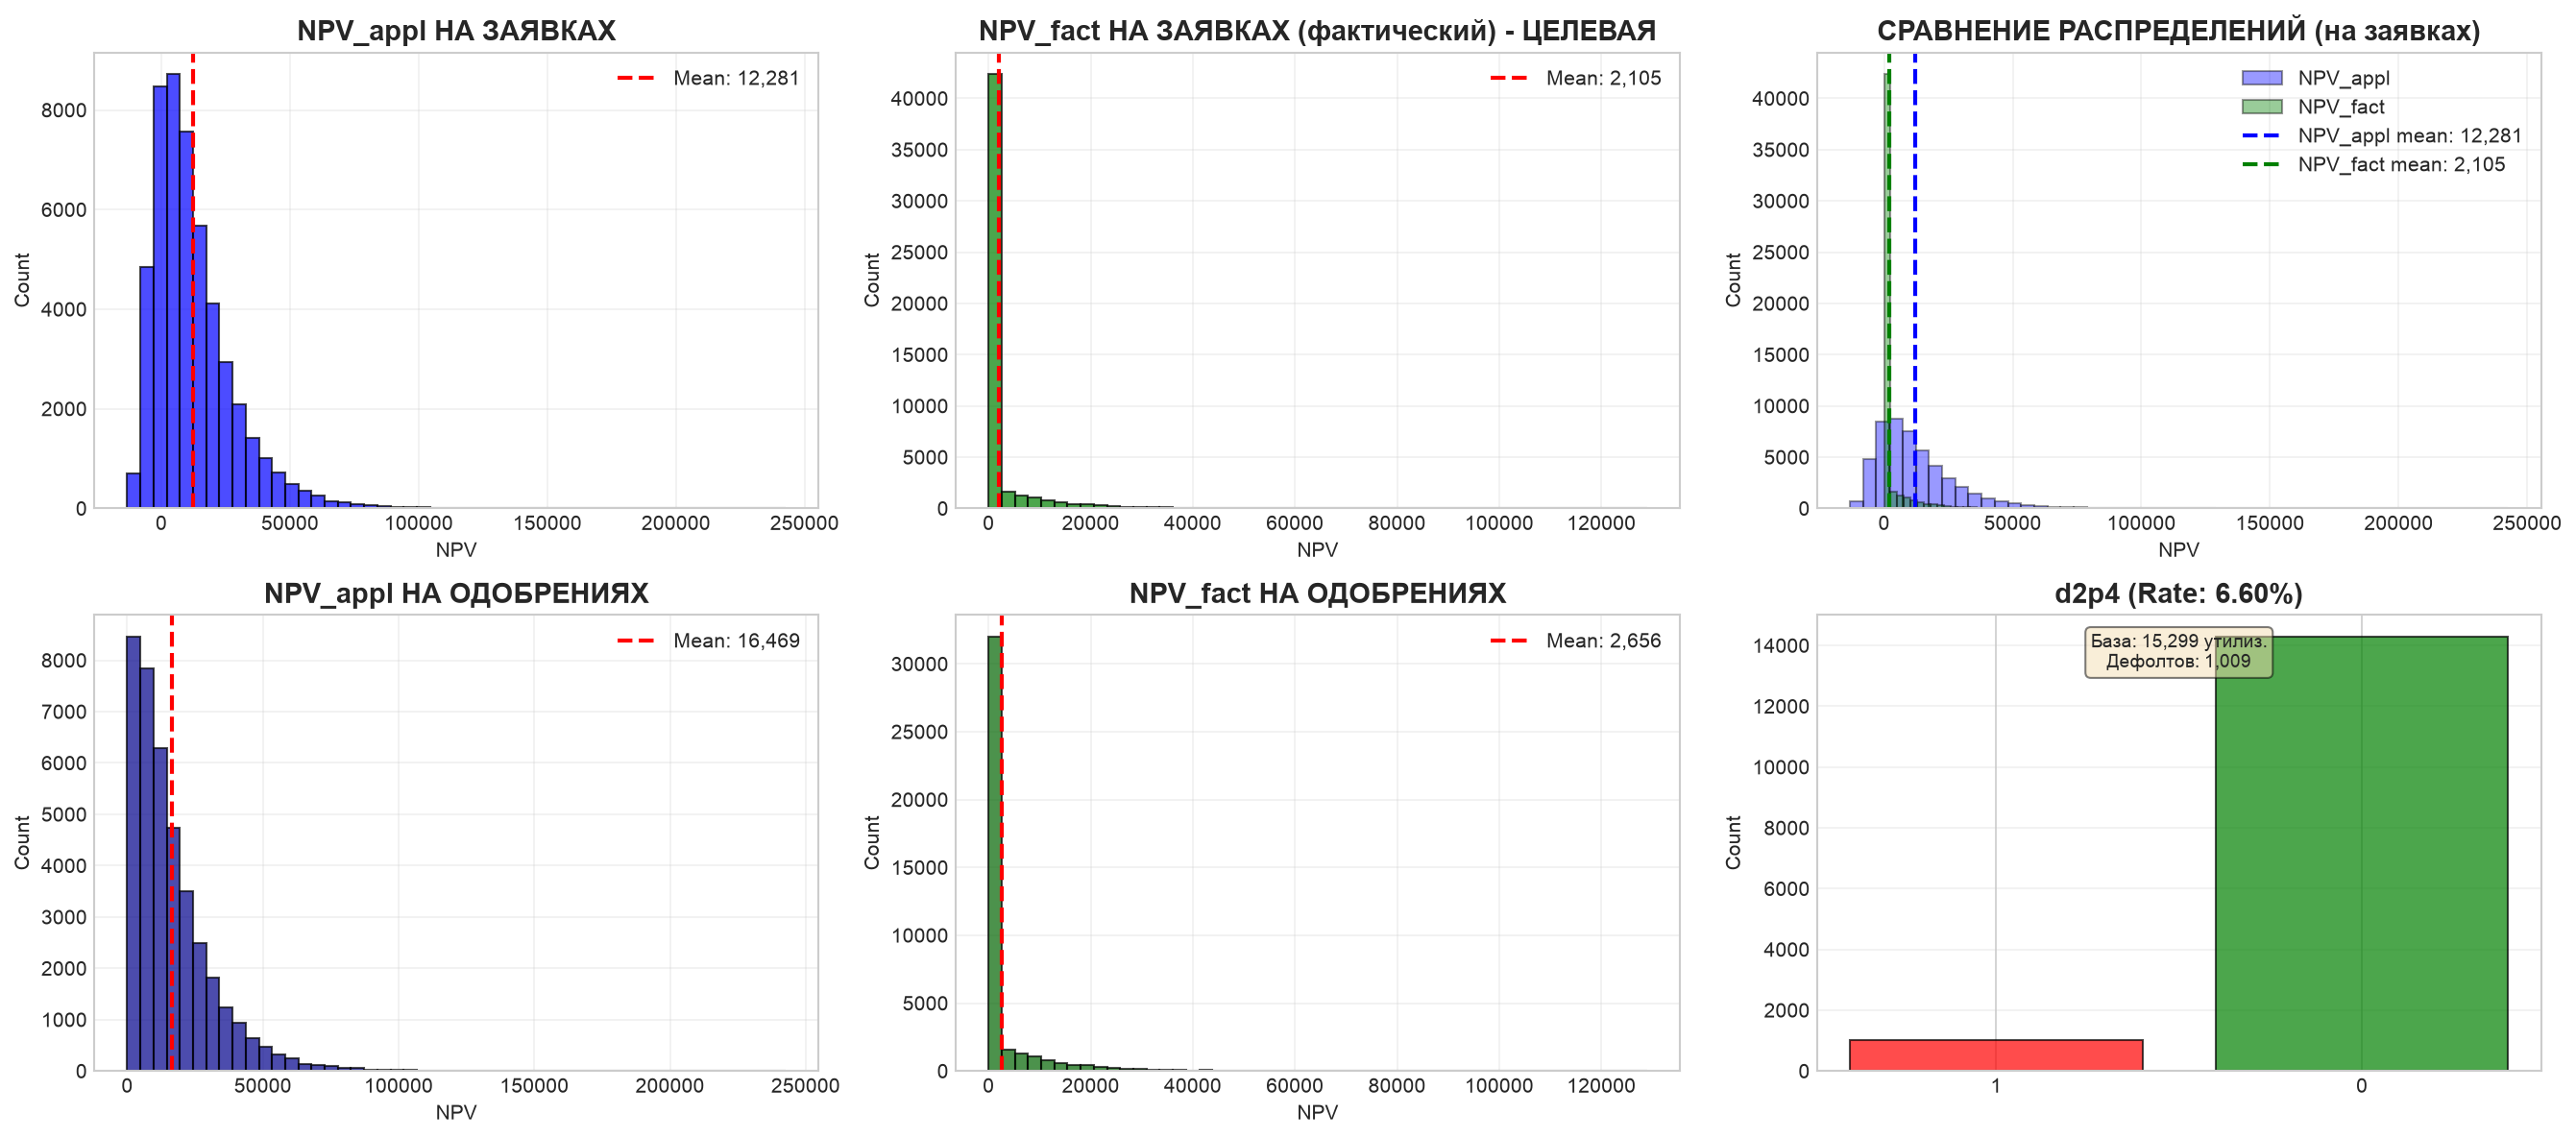

In [103]:
# Создаём подвыборки для анализа
approved = historical[historical['approve_flg'] == 1].copy()
utilized = historical[historical['take_flg'] == 1].copy()

print(f"\nРазмеры выборок:")
print(f"  - Всего заявок: {len(historical):,}")
print(f"  - Одобрено: {len(approved):,} ({len(approved)/len(historical)*100:.1f}%)")
print(f"  - Утилизировано: {len(utilized):,} ({len(utilized)/len(approved)*100:.1f}%)")

# Группировка по воронке
historical.groupby(
    ['approve_flg', 'take_flg']
)['financial_application_rk'].count()

# Визуализация распределений - сравнение NPV_appl vs NPV_fact

fig, axes = plt.subplots(2, 3, figsize=(18, 8), dpi=150)

# 1. NPV_appl на заявку (все заявки)
axes[0, 0].hist(historical['NPV_appl'], bins=50, edgecolor='black', alpha=0.7, color='blue')
axes[0, 0].axvline(historical['NPV_appl'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {historical["NPV_appl"].mean():,.0f}')
axes[0, 0].set_title('NPV_appl НА ЗАЯВКАХ', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('NPV')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. NPV_fact на заявку - ЦЕЛЕВАЯ МЕТРИКА (все заявки)
axes[0, 1].hist(historical['NPV_fact'], bins=50, edgecolor='black', alpha=0.7, color='green')
axes[0, 1].axvline(historical['NPV_fact'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {historical["NPV_fact"].mean():,.0f}')
axes[0, 1].set_title('NPV_fact НА ЗАЯВКАХ (фактический) - ЦЕЛЕВАЯ', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('NPV')
axes[0, 1].set_ylabel('Count')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Сравнение распределений NPV_appl vs NPV_fact (наложенные гистограммы)
axes[0, 2].hist(historical['NPV_appl'], bins=50, edgecolor='black', alpha=0.4, label='NPV_appl', color='blue')
axes[0, 2].hist(historical['NPV_fact'], bins=50, edgecolor='black', alpha=0.4, label='NPV_fact', color='green')
axes[0, 2].axvline(historical['NPV_appl'].mean(), color='blue', linestyle='--', linewidth=2, label=f'NPV_appl mean: {historical["NPV_appl"].mean():,.0f}')
axes[0, 2].axvline(historical['NPV_fact'].mean(), color='green', linestyle='--', linewidth=2, label=f'NPV_fact mean: {historical["NPV_fact"].mean():,.0f}')
axes[0, 2].set_title('СРАВНЕНИЕ РАСПРЕДЕЛЕНИЙ (на заявках)', fontsize=14, fontweight='bold')
axes[0, 2].set_xlabel('NPV')
axes[0, 2].set_ylabel('Count')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# 4. NPV_appl на одобрение (только одобренные)
axes[1, 0].hist(approved['NPV_appl'], bins=50, edgecolor='black', alpha=0.7, color='darkblue')
axes[1, 0].axvline(approved['NPV_appl'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {approved["NPV_appl"].mean():,.0f}')
axes[1, 0].set_title('NPV_appl НА ОДОБРЕНИЯХ', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('NPV')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 5. NPV_fact на одобрениЯХ (только одобренные)
axes[1, 1].hist(approved['NPV_fact'], bins=50, edgecolor='black', alpha=0.7, color='darkgreen')
axes[1, 1].axvline(approved['NPV_fact'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {approved["NPV_fact"].mean():,.0f}')
axes[1, 1].set_title('NPV_fact НА ОДОБРЕНИЯХ', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('NPV')
axes[1, 1].set_ylabel('Count')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# 6. d2p4 distribution - d2p4 считается ОТНОСИТЕЛЬНО УТИЛИЗИРОВАННЫХ
if 'd2p4' in utilized.columns:
    n_utilized = utilized['d2p4'].count()  # Количество утилизированных
    n_defaults = utilized['d2p4'].sum()  # Количество дефолтов среди утилизированных
    axes[1, 2].bar(['1', '0'], 
                   [n_defaults, n_utilized - n_defaults],
                   color=['red', 'green'], edgecolor='black', alpha=0.7)
    d2p4_rate = utilized['d2p4'].mean() * 100  # d2p4 rate среди утилизированных
    axes[1, 2].set_title(f'd2p4 (Rate: {d2p4_rate:.2f}%)', fontsize=14, fontweight='bold')
    axes[1, 2].set_ylabel('Count')
    axes[1, 2].text(0.5, n_utilized * 0.9, f'База: {n_utilized:,} утилиз.\nДефолтов: {n_defaults:,}', 
                    ha='center', va='center', fontsize=9, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    axes[1, 2].grid(True, alpha=0.3, axis='y')
else:
    axes[1, 2].text(0.5, 0.5, 'd2p4 not available', ha='center', va='center', fontsize=12)
    axes[1, 2].set_title('d2p4 Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../data/npv_comparison_distributions.png', dpi=150, bbox_inches='tight')
plt.show()


## 2.1. Анализ распределения лимитов

АНАЛИЗ РАСПРЕДЕЛЕНИЯ ЛИМИТОВ

1. ОБЩАЯ СТАТИСТИКА ЛИМИТОВ:
   Mean: 1,017,310
   Std:  540,557
   Median: 898,894
   Min: 96,302
   Max: 8,432,403
   Q25: 639,689
   Q75: 1,259,947

2. ЛИМИТЫ ПО ГРУППАМ:
   Одобрено (approve_flg=1): 1,162,621 ± 514,289
   Утилизировано (take_flg=1): 1,167,585 ± 516,001
   Не одобрено (approve_flg=0): 462,127 ± 95,717


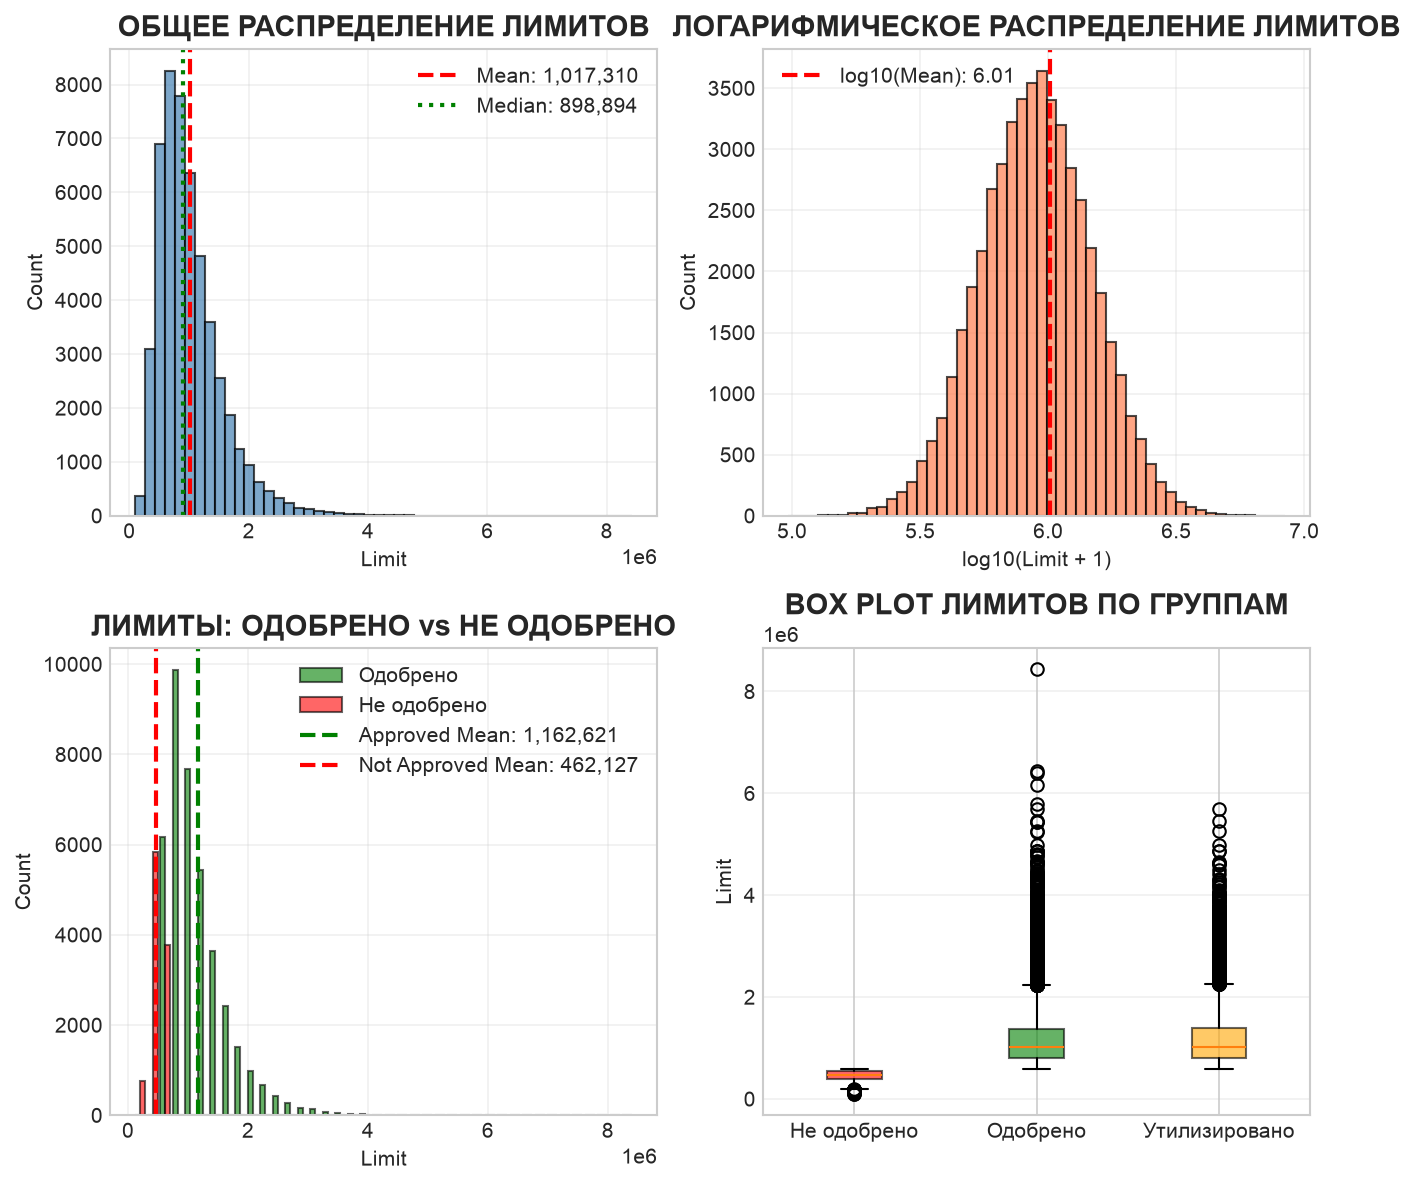

In [104]:
print("=" * 80)
print("АНАЛИЗ РАСПРЕДЕЛЕНИЯ ЛИМИТОВ")
print("=" * 80)

print("\n1. ОБЩАЯ СТАТИСТИКА ЛИМИТОВ:")
print(f"   Mean: {historical['limit'].mean():,.0f}")
print(f"   Std:  {historical['limit'].std():,.0f}")
print(f"   Median: {historical['limit'].median():,.0f}")
print(f"   Min: {historical['limit'].min():,.0f}")
print(f"   Max: {historical['limit'].max():,.0f}")
print(f"   Q25: {historical['limit'].quantile(0.25):,.0f}")
print(f"   Q75: {historical['limit'].quantile(0.75):,.0f}")

print("\n2. ЛИМИТЫ ПО ГРУППАМ:")
print(f"   Одобрено (approve_flg=1): {approved['limit'].mean():,.0f} ± {approved['limit'].std():,.0f}")
print(f"   Утилизировано (take_flg=1): {utilized['limit'].mean():,.0f} ± {utilized['limit'].std():,.0f}")
print(f"   Не одобрено (approve_flg=0): {historical[historical['approve_flg']==0]['limit'].mean():,.0f} ± {historical[historical['approve_flg']==0]['limit'].std():,.0f}")

# Визуализация распределения лимитов
fig, axes = plt.subplots(2, 2, figsize=(9, 8), dpi=150)

# 1. Гистограмма всех лимитов
axes[0, 0].hist(historical['limit'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(historical['limit'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {historical["limit"].mean():,.0f}')
axes[0, 0].axvline(historical['limit'].median(), color='green', linestyle=':', linewidth=2, label=f'Median: {historical["limit"].median():,.0f}')
axes[0, 0].set_title('ОБЩЕЕ РАСПРЕДЕЛЕНИЕ ЛИМИТОВ', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Limit')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Логарифмическая гистограмма (для лучшей видимости)
axes[0, 1].hist(np.log10(historical['limit'] + 1), bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].axvline(np.log10(historical['limit'].mean() + 1), color='red', linestyle='--', linewidth=2, label=f'log10(Mean): {np.log10(historical["limit"].mean() + 1):.2f}')
axes[0, 1].set_title('ЛОГАРИФМИЧЕСКОЕ РАСПРЕДЕЛЕНИЕ ЛИМИТОВ', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('log10(Limit + 1)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Сравнение лимитов по группам (одобрено/не одобрено)
approved_limits = approved['limit']
not_approved_limits = historical[historical['approve_flg']==0]['limit']
axes[1, 0].hist([approved_limits, not_approved_limits], bins=40, edgecolor='black', alpha=0.6, 
                label=['Одобрено', 'Не одобрено'], color=['green', 'red'])
axes[1, 0].axvline(approved_limits.mean(), color='green', linestyle='--', linewidth=2, label=f'Approved Mean: {approved_limits.mean():,.0f}')
axes[1, 0].axvline(not_approved_limits.mean(), color='red', linestyle='--', linewidth=2, label=f'Not Approved Mean: {not_approved_limits.mean():,.0f}')
axes[1, 0].set_title('ЛИМИТЫ: ОДОБРЕНО vs НЕ ОДОБРЕНО', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Limit')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Box plot лимитов по группам
group_data = [
    historical[historical['approve_flg']==0]['limit'],
    approved['limit'],
    utilized['limit']
]
bp = axes[1, 1].boxplot(group_data, patch_artist=True)
colors = ['red', 'green', 'orange']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[1, 1].set_xticklabels(['Не одобрено', 'Одобрено', 'Утилизировано'])
axes[1, 1].set_title('BOX PLOT ЛИМИТОВ ПО ГРУППАМ', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Limit')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../data/limits_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Расчёт размера выборки для A/B теста


In [105]:
def calculate_sample_size(mean_ref, std_ref, mde_percent, alpha=0.05, power=0.8, ratio=1):
    """
    Расчёт размера выборки для детектирования эффекта MDE.
    
    Parameters:
    -----------
    mean_ref : float
        Среднее значение в контрольной группе
    std_ref : float
        Стандартное отклонение в контрольной группе
    mde_percent : float
        Минимальный детектируемый эффект в процентах (например, 5 для 5%)
    alpha : float
        Уровень значимости (по умолчанию 0.05)
    power : float
        Статистическая мощность (по умолчанию 0.8)
    ratio : float
        Отношение размера treatment к control (по умолчанию 1)
    
    Returns:
    --------
    dict : Результаты расчёта
    """
    # Эффект в абсолютных единицах
    effect_size = abs(mde_percent / 100 * mean_ref)
    
    # Cohen's d
    cohens_d = effect_size / std_ref
    
    # Расчёт размера выборки
    power_analysis = TTestIndPower()
    n_per_group = power_analysis.solve_power(
        effect_size=cohens_d,
        alpha=alpha,
        power=power,
        ratio=ratio,
        alternative='two-sided'
    )
    
    return {
        'mean_ref': mean_ref,
        'std_ref': std_ref,
        'mde_percent': mde_percent,
        'effect_size_abs': effect_size,
        # 'cohens_d': cohens_d,
        'n_per_group': int(np.ceil(n_per_group)),
        'n_total': int(np.ceil(n_per_group * 2))
    }


def calculate_sample_size_proportion(p_ref, mde_percent, alpha=0.05, power=0.8, ratio=1):
    """
    Расчёт размера выборки для пропорций (конверсий).
    
    Parameters:
    -----------
    p_ref : float
        Базовая пропорция (например, 0.08 для 8%)
    mde_percent : float
        Минимальный детектируемый эффект в процентах (например, 10 для 10% относительного изменения)
    alpha : float
        Уровень значимости (по умолчанию 0.05)
    power : float
        Статистическая мощность (по умолчанию 0.8)
    ratio : float
        Отношение размера treatment к control (по умолчанию 1)
    
    Returns:
    --------
    dict : Результаты расчёта
    """
    # Абсолютное изменение пропорции
    p_treatment = p_ref * (1 + mde_percent / 100)
    
    # Эффект через pooled proportion
    p_pool = (p_ref + p_treatment) / 2
    effect_size = (p_ref - p_treatment) / np.sqrt(p_pool * (1 - p_pool))
    
    # Расчёт размера выборки
    power_analysis = NormalIndPower()
    n_per_group = power_analysis.solve_power(
        effect_size=abs(effect_size),
        alpha=alpha,
        power=power,
        ratio=ratio,
        alternative='two-sided'
    )
    
    return {
        'p_ref': p_ref,
        'p_treatment': p_treatment,
        'mde_percent': mde_percent,
        'effect_size': abs(effect_size),
        'n_per_group': int(np.ceil(n_per_group)),
        'n_total': int(np.ceil(n_per_group * 2))
    }

In [106]:
# Параметры для расчёта
alpha = 0.05      # Уровень значимости (5%)
power = 0.8       # Статистическая мощность (80%)

# Сценарии MDE
mde_scenarios = [3, 5, 10, 15, 20]  # Проценты

print("=" * 100)
print("РАСЧЁТ РАЗМЕРА ВЫБОРКИ ДЛЯ NPV_fact (ЦЕЛЕВАЯ МЕТРИКА)")
print("=" * 100)

# Для разных метрик - ТЕПЕРЬ С УПОРОМ НА NPV_fact
metrics = {
    'NPV_fact (на заявку) - ЦЕЛЕВАЯ': historical['NPV_fact'],
}

results = {}

for metric_name, metric_data in metrics.items():
    mean_ref = metric_data.mean()
    std_ref = metric_data.std()
    
    print(f"\n{metric_name}:")
    print(f"  Mean: {mean_ref:,.0f}, Std: {std_ref:,.0f}")
    print(f"  {'MDE':<6} | {'Effect':<10} | {'N per group':<12} | {'N total':<10}")
    print(f"  {'%':<6} | {'(abs)':<10} | {'':<12} | {'':<10}")
    print("  " + "-" * 60)
    
    results[metric_name] = []
    
    for mde in mde_scenarios:
        calc = calculate_sample_size(mean_ref, std_ref, mde, alpha, power)
        results[metric_name].append(calc)
        print(f"  {mde:<6} | {calc['effect_size_abs']:>10,.0f} | {calc['n_per_group']:>12,} | {calc['n_total']:>10,}")

print("\n" + "=" * 100)

РАСЧЁТ РАЗМЕРА ВЫБОРКИ ДЛЯ NPV_fact (ЦЕЛЕВАЯ МЕТРИКА)

NPV_fact (на заявку) - ЦЕЛЕВАЯ:
  Mean: 2,105, Std: 6,547
  MDE    | Effect     | N per group  | N total   
  %      | (abs)      |              |           
  ------------------------------------------------------------
  3      |         63 |      168,704 |    337,407
  5      |        105 |       60,734 |    121,468
  10     |        211 |       15,185 |     30,369
  15     |        316 |        6,750 |     13,499
  20     |        421 |        3,797 |      7,594



## 4. Визуализация зависимости размера выборки от MDE

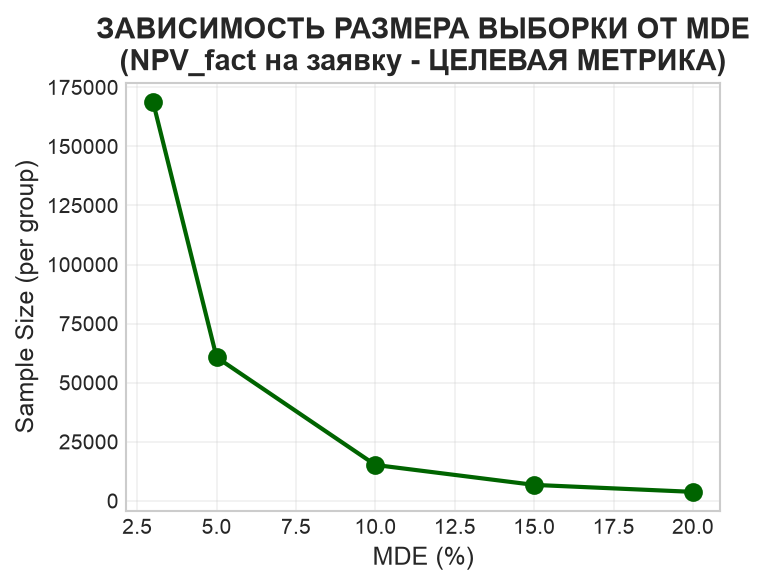

In [107]:
# Визуализация зависимости размера выборки от MDE для разных метрик

fig, axes = plt.subplots(1, 1, figsize=(5, 4), dpi=150)

# 1. Основная кривая: Sample Size vs MDE для NPV_fact (на заявку) - ЦЕЛЕВАЯ МЕТРИКА
ax = axes
mde_values = [calc['mde_percent'] for calc in results['NPV_fact (на заявку) - ЦЕЛЕВАЯ']]
n_values = [calc['n_per_group'] for calc in results['NPV_fact (на заявку) - ЦЕЛЕВАЯ']]

ax.plot(mde_values, n_values, marker='o', linewidth=2, markersize=8, color='darkgreen')

ax.set_title('ЗАВИСИМОСТЬ РАЗМЕРА ВЫБОРКИ ОТ MDE\n(NPV_fact на заявку - ЦЕЛЕВАЯ МЕТРИКА)', fontsize=14, fontweight='bold')
ax.set_xlabel('MDE (%)', fontsize=12)
ax.set_ylabel('Sample Size (per group)', fontsize=12)
ax.grid(True, alpha=0.3)


plt.tight_layout()
plt.savefig('../data/sample_size_vs_mde.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Расчёт длительности теста

ЗАВИСИМОСТЬ ДЛИТЕЛЬНОСТИ ТЕСТА ОТ MDE (NPV_fact на заявку)
Трафик: 1,667 заявок/день, доля в тесте: 100%, вызревание: 120 дн.
MDE %   |    N total |  Набор, дн | Набор, нед |  Итого, дн
------------------------------------------------------------------------------------------
3       |    337,407 |        203 |       29.0 |        323
5       |    121,468 |         73 |       10.4 |        193
10      |     30,369 |         19 |        2.7 |        139
15      |     13,499 |          9 |        1.3 |        129
20      |      7,594 |          5 |        0.7 |        125


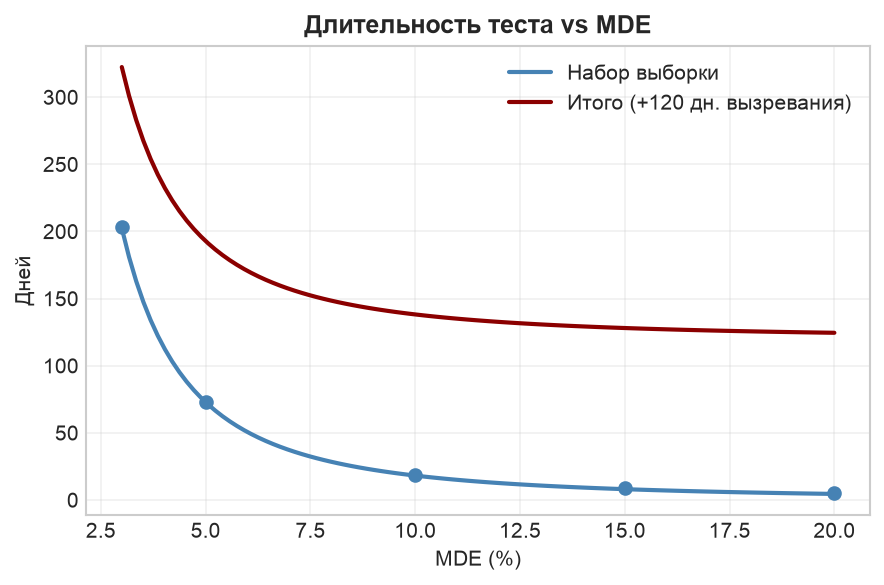

In [108]:
# Параметры
daily_traffic = daily_apps.mean()      # ~1 667 заявок/день из исторических данных
traffic_share = 1.0                    # доля трафика, направляемая в эксперимент (обе группы)
maturation_days = 120                  # окно вызревания NPV_fact / d2p4 (4 месяца)

print("=" * 90)
print("ЗАВИСИМОСТЬ ДЛИТЕЛЬНОСТИ ТЕСТА ОТ MDE (NPV_fact на заявку)")
print(f"Трафик: {daily_traffic:,.0f} заявок/день, доля в тесте: {traffic_share:.0%}, "
      f"вызревание: {maturation_days} дн.")
print("=" * 90)
print(f"{'MDE %':<7} | {'N total':>10} | {'Набор, дн':>10} | {'Набор, нед':>10} | {'Итого, дн':>10}")
print("-" * 90)

durations = []
for calc in results['NPV_fact (на заявку) - ЦЕЛЕВАЯ']:
    recruit_days = np.ceil(calc['n_total'] / (daily_traffic * traffic_share))
    total_days = recruit_days + maturation_days
    durations.append({'mde': calc['mde_percent'], 'n_total': calc['n_total'],
                      'recruit_days': recruit_days, 'total_days': total_days})
    print(f"{calc['mde_percent']:<7} | {calc['n_total']:>10,} | {recruit_days:>10.0f} | "
          f"{recruit_days/7:>10.1f} | {total_days:>10.0f}")

# Визуализация
mde_grid = np.linspace(3, 20, 100)
base = results['NPV_fact (на заявку) - ЦЕЛЕВАЯ'][0]          # точка MDE=3%
n_grid = base['n_total'] * (base['mde_percent'] / mde_grid) ** 2   # N ∝ 1/MDE²
recruit_grid = n_grid / (daily_traffic * traffic_share)

fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
ax.plot(mde_grid, recruit_grid, color='steelblue', lw=2, label='Набор выборки')
ax.plot(mde_grid, recruit_grid + maturation_days, color='darkred', lw=2,
        label=f'Итого (+{maturation_days} дн. вызревания)')
ax.scatter([d['mde'] for d in durations], [d['recruit_days'] for d in durations],
           color='steelblue', zorder=3)
ax.set_title('Длительность теста vs MDE',
             fontsize=12, fontweight='bold')
ax.set_xlabel('MDE (%)'); ax.set_ylabel('Дней')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../data/duration_vs_mde.png', dpi=150, bbox_inches='tight')
plt.show()